In [195]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import seaborn as sns
import folium as fs
import numpy as np

In [2]:
df=pd.read_csv("Dataset .csv")

In [136]:
df

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes,Cluster
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Yes,No,No,No,3,4.8,Dark Green,5,314,0
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Yes,No,No,No,3,4.5,Dark Green,5,591,0
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Yes,No,No,No,4,4.4,Green,4,270,0
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,No,No,No,No,4,4.9,Dark Green,5,365,0
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Yes,No,No,No,4,4.8,Dark Green,5,229,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9546,5915730,Naml۱ Gurme,208,stanbul,"Kemanke Karamustafa Paa Mahallesi, R۱ht۱m Cadd...",Karak_y,"Karak_y, stanbul",28.977392,41.022793,Turkish,...,No,No,No,No,3,4.1,Green,4,788,4
9547,5908749,Ceviz Aac۱,208,stanbul,"Kouyolu Mahallesi, Muhittin st_nda Caddesi, No...",Kouyolu,"Kouyolu, stanbul",29.041297,41.009847,"World Cuisine, Patisserie, Cafe",...,No,No,No,No,3,4.2,Green,4,1034,4
9548,5915807,Huqqa,208,stanbul,"Kuru_eme Mahallesi, Muallim Naci Caddesi, No 5...",Kuru_eme,"Kuru_eme, stanbul",29.034640,41.055817,"Italian, World Cuisine",...,No,No,No,No,4,3.7,Yellow,3,661,4
9549,5916112,Ak Kahve,208,stanbul,"Kuru_eme Mahallesi, Muallim Naci Caddesi, No 6...",Kuru_eme,"Kuru_eme, stanbul",29.036019,41.057979,Restaurant Cafe,...,No,No,No,No,4,4.0,Green,4,901,4


In [23]:
df.isnull().sum()

Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                0
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64

In [5]:
df['Restaurant Name'] = df['Restaurant Name'].str.replace("�","",regex=False)

In [6]:
df['City'] = df['City'].str.replace("�","",regex=False)

In [7]:
df['Address'] = df['Address'].str.replace("�","",regex=False)

In [8]:
df['Locality'] = df['Locality'].str.replace("�","",regex=False)

In [9]:
df['Locality Verbose'] = df['Locality Verbose'].str.replace("�","",regex=False)

In [10]:
df.dropna(inplace=True)

LEVEL 3 TASK 1 RESTURANT REVIEWS

In [149]:
df['Rating text'].dtype

dtype('int64')

In [124]:
df['Rating text']=df['Rating text'].str.replace('Not rated','0',regex=False)

In [125]:
df['Rating text']=df['Rating text'].str.replace('Poor','1',regex=False)

In [126]:
df['Rating text']=df['Rating text'].str.replace('Average','2',regex=False)

In [127]:
df['Rating text']=df['Rating text'].str.replace('Good','3',regex=False)

In [131]:
df['Rating text']=df['Rating text'].str.replace('Very 3','4',regex=False)

In [129]:
df['Rating text']=df['Rating text'].str.replace('Excellent','5',regex=False)

In [148]:
df['Rating text']=df['Rating text'].astype(int)

Text(0, 0.5, 'Outcomes')

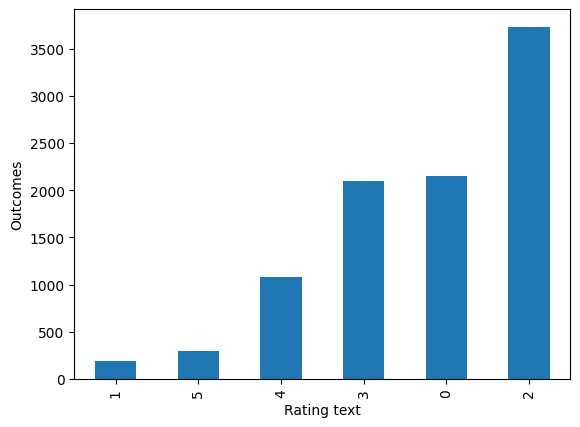

In [142]:
df['Rating text'].value_counts().sort_values(ascending=True).plot(kind='bar')
plt.ylabel('Outcomes')

In [150]:
df['Rating text'].mean()

np.float64(2.0702158876545798)

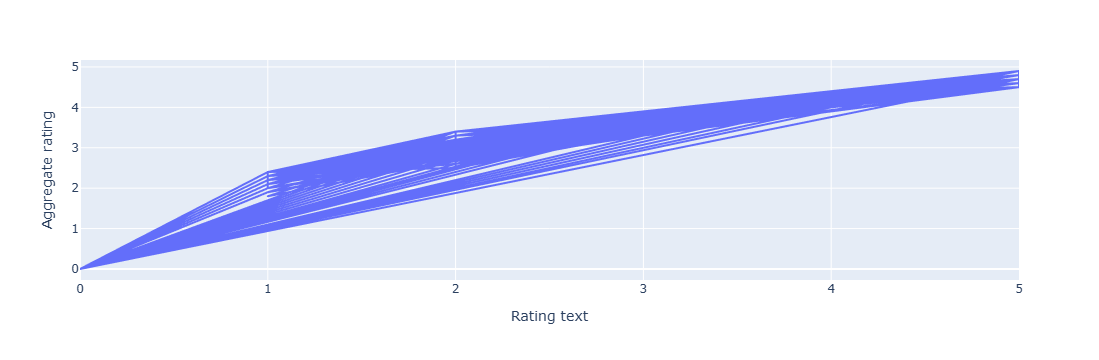

In [151]:
px.line(df,x='Rating text',y='Aggregate rating')

TASK 2 VOTE ANALYSIS

In [155]:
df[['Votes','Restaurant Name']].sort_values('Votes',ascending=False)

,Votes,Restaurant Name
728,10934,Toit
735,9667,Truffles
3994,7931,Hauz Khas Social
2412,7574,Peter Cat
739,6907,AB's - Absolute Barbecues
...,...,...
1948,0,Chinese Fast Food
6877,0,Shree Balaji Bhojnalaya
3603,0,Foodies
3633,0,Punjabi's Veg Grill


In [156]:
df[['Votes','Restaurant Name']].sort_values('Votes',ascending=False).head(1)

,Votes,Restaurant Name
728,10934,Toit


In [172]:
k=df[['Votes','Restaurant Name']]

In [175]:
k[k['Votes']==0]

,Votes,Restaurant Name
69,0,Cantinho da Gula
874,0,The Chaiwalas
879,0,Fusion Food Corner
880,0,Punjabi Rasoi
887,0,Baskin Robbin
...,...,...
9044,0,6 Packs Momos
9098,0,Cafe' Wow
9099,0,Chef's Basket Pop Up Caf
9103,0,The Hangout-Deli


Text(0.5, 1.0, 'Correlation heatmap btw votes and rating of a resturant')

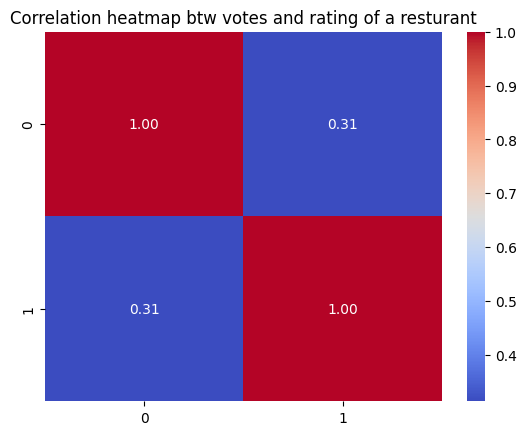

In [179]:
l=list(df['Aggregate rating'])
m=list(df['Votes'])
x=np.corrcoef(l,m)
sns.heatmap(x, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation heatmap btw votes and rating of a resturant')

TASK 3 Price Range vs. Online Delivery and Table Booking

In [183]:
a=pd.crosstab(df['Has Table booking'],df['Has Online delivery'])
print('online delivery v/s Table booking\n',a)

online delivery v/s Table booking
 Has Online delivery    No   Yes
Has Table booking              
No                   6368  2016
Yes                   723   435


In [189]:
b=pd.crosstab(df['Price range'],df['Has Online delivery'],normalize='index')*100
print('Price range v/s Has online delivery\n',b)

Price range v/s Has online delivery
 Has Online delivery         No        Yes
Price range                              
1                    84.204597  15.795403
2                    58.689367  41.310633
3                    70.747331  29.252669
4                    90.955631   9.044369


Text(0.5, 1.0, 'Price range v/s Has online delivery')

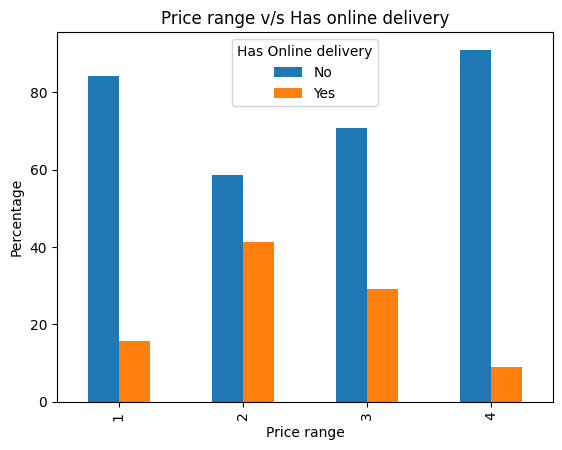

In [192]:
b.plot(kind='bar')
plt.ylabel('Percentage')
plt.title('Price range v/s Has online delivery')

Text(0.5, 1.0, 'Has Table Booking v/s Has online delivery')

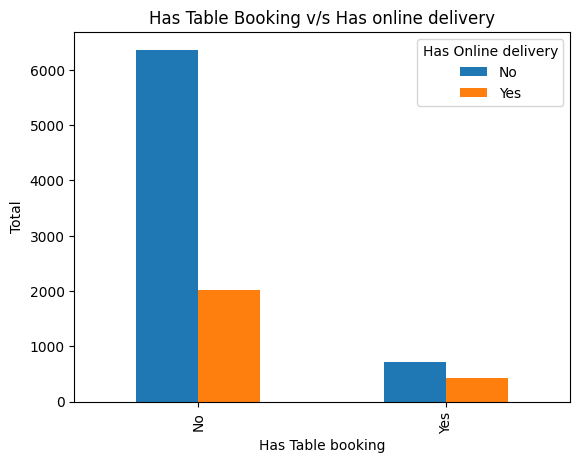

In [194]:
a.plot(kind='bar')
plt.ylabel('Total')
plt.title('Has Table Booking v/s Has online delivery')